# English → Kannada Machine Translation (ICT4403 Assignment 3)

**Models:** Basic Transformer (from scratch), mT5-small (fine-tuned), TinyLlama (optional prompt-only), Gemma (optional prompt-only).

**Dataset:** Kaggle English-to-Kannada parallel text dataset  
https://www.kaggle.com/datasets/parvmodi/english-to-kannada-machine-translation-dataset

**Runtime:** Kaggle Notebook with GPU enabled (Tesla T4 recommended).

> Reproducibility notes:
> - This notebook creates a manageable aligned subset from `train.en` and `train.kn`.
> - Both trainable models use the same train/validation/test split.
> - Decoder-only LLM sections are optional and disabled by default because access, package compatibility, and GPU runtime can vary.
> - BLEU and chrF are computed on the same test subset for all models that complete.

In [45]:
import sys
print("Python:", sys.version)

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 1. Install dependencies

In [46]:
%pip install -q -U transformers datasets sentencepiece sacrebleu accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## 2. Imports, seed, GPU check

In [47]:
import os, json, time, random, math, gc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
from sacrebleu import corpus_bleu, corpus_chrf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("WARNING: Enable GPU in Kaggle Settings → Accelerator → GPU.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
VRAM GB: 14.56


## 3. Find dataset files and inspect aligned examples

In [48]:
# Kaggle dataset path based on the dataset attached in this notebook.
DATA_DIR = Path("/kaggle/input/datasets/parvmodi/english-to-kannada-machine-translation-dataset")
EN_PATH = DATA_DIR / "train.en"
KN_PATH = DATA_DIR / "train.kn"

# Fallback search in case Kaggle mounts the dataset at a different path.
if not EN_PATH.exists() or not KN_PATH.exists():
    candidates = list(Path("/kaggle/input").rglob("train.en"))
    if not candidates:
        raise FileNotFoundError("Could not find train.en under /kaggle/input. Check that the dataset is attached.")
    EN_PATH = candidates[0]
    KN_PATH = EN_PATH.with_name("train.kn")

print("English file:", EN_PATH)
print("Kannada file:", KN_PATH)
print("English size MB:", round(EN_PATH.stat().st_size / 1e6, 2))
print("Kannada size MB:", round(KN_PATH.stat().st_size / 1e6, 2))

with open(EN_PATH, encoding="utf-8") as f_en, open(KN_PATH, encoding="utf-8") as f_kn:
    for i in range(5):
        en, kn = next(f_en).strip(), next(f_kn).strip()
        print(f"\nExample {i+1}\nEN: {en}\nKN: {kn}")

English file: /kaggle/input/datasets/parvmodi/english-to-kannada-machine-translation-dataset/train.en
Kannada file: /kaggle/input/datasets/parvmodi/english-to-kannada-machine-translation-dataset/train.kn
English size MB: 225.14
Kannada size MB: 625.6

Example 1
EN: Hes a scientist.
KN: ಇವರು ಸಂಶೋಧಕ ಸ್ವಭಾವದವರು.

Example 2
EN: 'But we speak the truth aur ye sach hai ke Gujarat mein vikas pagal hogaya hai,'' Rahul Gandhi further said in Banaskantha
KN: "ಆದರೆ ಸತ್ಯ ಹೊರ ಬಂದೇ ಬರುತ್ತದೆ ಎಂದು ಹೇಳಿದ ರಾಹುಲ್ ಗಾಂಧಿ, ""ಸೂರತ್ ಜನರು ಚೀನಾದ ಜತೆ ಸ್ಪರ್ಧೆ ನಡೆಸುತ್ತಿದ್ದಾರೆ"

Example 3
EN: 8 lakh crore have been looted.
KN: ಕಳ್ಳತನವಾಗಿದ್ದ 8 ಲಕ್ಷ ರೂ.

Example 4
EN: I read a lot into this as well.
KN: ಇದರ ಬಗ್ಗೆ ನಾನೂ ಸಾಕಷ್ಟು ಓದಿದ್ದೇನೆ.

Example 5
EN: She was found dead with the phone's battery exploded close to her head the following morning.
KN: ಆಕೆಯ ತಲೆಯ ಹತ್ತಿರ ಇರಿಸಿಕೊಂಡಿದ್ದ ಫೋನ್‌ನ ಬ್ಯಾಟರಿ ಸ್ಫೋಟಗೊಂಡು ಆಕೆ ಮೃತಪಟ್ಟಿದ್ದಾಳೆ ಎನ್ನಲಾಗಿದೆ.


## 4. Build a manageable aligned subset and split

In [49]:
# Use a deterministic random sample from the parallel files without loading all 4M pairs into RAM.
# Reservoir sampling gives a representative sample across the file, rather than only the first rows.
MAX_SAMPLES = 20000
reservoir = []
seen = 0

with open(EN_PATH, encoding="utf-8") as f_en, open(KN_PATH, encoding="utf-8") as f_kn:
    for line_no, (en, kn) in enumerate(zip(f_en, f_kn)):
        en, kn = en.strip(), kn.strip()
        if not en or not kn:
            continue
        seen += 1
        item = (en, kn)
        if len(reservoir) < MAX_SAMPLES:
            reservoir.append(item)
        else:
            j = random.randrange(seen)
            if j < MAX_SAMPLES:
                reservoir[j] = item

df = pd.DataFrame(reservoir, columns=["english", "kannada"])
df = df.drop_duplicates().reset_index(drop=True)
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

os.makedirs("/kaggle/working/assignment3_outputs", exist_ok=True)
OUT_DIR = Path("/kaggle/working/assignment3_outputs")
df.to_csv(OUT_DIR / "dataset_subset.csv", index=False, encoding="utf-8-sig")
train_df.to_csv(OUT_DIR / "train.csv", index=False, encoding="utf-8-sig")
val_df.to_csv(OUT_DIR / "validation.csv", index=False, encoding="utf-8-sig")
test_df.to_csv(OUT_DIR / "test.csv", index=False, encoding="utf-8-sig")

print("Subset rows:", len(df))
print("Train:", len(train_df), "Validation:", len(val_df), "Test:", len(test_df))
print("Duplicate pairs after cleaning:", df.duplicated().sum())
display(df.head())

Subset rows: 20000
Train: 16000 Validation: 2000 Test: 2000
Duplicate pairs after cleaning: 0


,english,kannada
0,"Once a upon time, actor JD Chakravarthy used t...","ಒಂದು ಕಾಲದಲ್ಲಿ, ರೊಮ್ಯಾಂಟಿಕ್ ಚಲನಚಿತ್ರಗಳಿಗೆ ನಟಿಸಲ..."
1,It poses a risk of cancer.,ಅದರಿಂದ ಕ್ಯಾನ್ಸರ್‌ ಬರುವ ಸಾಧ್ಯತೆ ಹೆಚ್ಚಿದೆ.
2,"New Zealand, who won the toss, chose to field ...",ಟಾಸ್ ಗೆದ್ದ ನ್ಯೂಜಿಲೆಂಡ್ ತಂಡ ಮೊದಲು ಬ್ಯಾಟಿಂಗ್ ಆಯ್...
3,Office Assistant : 1,ಕಾನೂನು ಸಹಾಯಕ: 1
4,I dont sleep at night.,‘ನಾನು ಈ ರಾತ್ರಿ ಮಲಗುವುದಿಲ್ಲ.


## 5. Evaluation helper

In [50]:
def score_translations(predictions, references):
    # sacreBLEU corpus BLEU and chrF use the same reference ordering.
    return {
        "BLEU": round(corpus_bleu(predictions, [references]).score, 2),
        "chrF": round(corpus_chrf(predictions, [references]).score, 2)
    }

results_rows = []

def add_result(model_name, params, train_minutes, predictions, references, inference_seconds, test_count=None):
    scores = score_translations(predictions, references)
    row = {
        "Model": model_name,
        "Parameters": int(params) if params is not None else None,
        "Training_Time_Min": round(float(train_minutes), 3) if train_minutes is not None else None,
        "BLEU": scores["BLEU"],
        "chrF": scores["chrF"],
        "Inference_Time_Per_Sentence_Sec": round(inference_seconds / max(len(predictions), 1), 4),
        "Test_Samples": len(predictions) if test_count is None else int(test_count)
    }
    results_rows.append(row)
    pd.DataFrame(results_rows).to_csv(OUT_DIR / "model_comparison.csv", index=False)
    return row

## 6. Model 1 — mT5-small fine-tuning

In [51]:
from datasets import Dataset
from transformers import AutoTokenizer, MT5ForConditionalGeneration
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, DataCollatorForSeq2Seq

MT5_NAME = "google/mt5-small"
MAX_TOKENS = 64
TRAIN_MTS5 = True

mt5_tokenizer = AutoTokenizer.from_pretrained(MT5_NAME)
mt5_model = MT5ForConditionalGeneration.from_pretrained(MT5_NAME).to(device)

train_ds = Dataset.from_pandas(train_df[["english","kannada"]].reset_index(drop=True), preserve_index=False)
val_ds = Dataset.from_pandas(val_df[["english","kannada"]].reset_index(drop=True), preserve_index=False)

def preprocess_mt5(batch):
    inputs = mt5_tokenizer(
        ["translate English to Kannada: " + x for x in batch["english"]],
        max_length=MAX_TOKENS, truncation=True
    )
    labels = mt5_tokenizer(
        text_target=batch["kannada"],
        max_length=MAX_TOKENS, truncation=True
    )
    inputs["labels"] = labels["input_ids"]
    return inputs

token_train = train_ds.map(preprocess_mt5, batched=True, remove_columns=train_ds.column_names)
token_val = val_ds.map(preprocess_mt5, batched=True, remove_columns=val_ds.column_names)

collator = DataCollatorForSeq2Seq(tokenizer=mt5_tokenizer, model=mt5_model)
args = Seq2SeqTrainingArguments(
    output_dir=str(OUT_DIR / "mt5_checkpoints"),
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=2,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    predict_with_generate=False,
    logging_steps=100,
    save_total_limit=2,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    seed=SEED
)

trainer = Seq2SeqTrainer(
    model=mt5_model,
    args=args,
    train_dataset=token_train,
    eval_dataset=token_val,
    processing_class=mt5_tokenizer,
    data_collator=collator
)

mt5_training_seconds = 0.0
if TRAIN_MTS5:
    t0 = time.time()
    trainer.train()
    mt5_training_seconds = time.time() - t0
    trainer.save_model(str(OUT_DIR / "mt5_model"))
    mt5_tokenizer.save_pretrained(str(OUT_DIR / "mt5_model"))
    print("mT5 training minutes:", round(mt5_training_seconds/60, 2))
else:
    print("Set TRAIN_MTS5=True to fine-tune. If resuming, load saved model/tokenizer from OUT_DIR / 'mt5_model'.")

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

mT5 training minutes: 33.03


In [52]:
import os

checkpoint_dir = "/kaggle/working/assignment3_outputs/mt5_checkpoints"

for root, dirs, files in os.walk(checkpoint_dir):
    for d in dirs:
        if d.startswith("checkpoint-"):
            print("Found checkpoint:", os.path.join(root, d))

Found checkpoint: /kaggle/working/assignment3_outputs/mt5_checkpoints/checkpoint-1000
Found checkpoint: /kaggle/working/assignment3_outputs/mt5_checkpoints/checkpoint-500


## 7. Evaluate mT5 on the shared test set

In [53]:
def mt5_translate(text):
    mt5_model.eval()
    encoded = mt5_tokenizer(
        "translate English to Kannada: " + str(text),
        return_tensors="pt", max_length=MAX_TOKENS, truncation=True
    ).to(device)
    with torch.inference_mode():
        out = mt5_model.generate(**encoded, max_new_tokens=MAX_TOKENS, num_beams=2)
    return mt5_tokenizer.decode(out[0], skip_special_tokens=True).strip()

# Start with 200 examples for a practical runtime; raise to len(test_df) for final evaluation if time permits.
EVAL_N = min(200, len(test_df))
eval_df = test_df.head(EVAL_N).reset_index(drop=True)
references = eval_df["kannada"].astype(str).tolist()

mt5_predictions = []
t0 = time.time()
for i, text in enumerate(eval_df["english"].astype(str), 1):
    mt5_predictions.append(mt5_translate(text))
    if i % 25 == 0:
        print(f"mT5 evaluated {i}/{EVAL_N}")
mt5_inference_seconds = time.time() - t0

mt5_row = add_result(
    "mT5-small", sum(p.numel() for p in mt5_model.parameters()),
    mt5_training_seconds/60, mt5_predictions, references,
    mt5_inference_seconds
)
print(mt5_row)
pd.DataFrame({"English": eval_df["english"], "Prediction": mt5_predictions, "Reference": references}).to_csv(
    OUT_DIR / "mt5_predictions.csv", index=False, encoding="utf-8-sig"
)

mT5 evaluated 25/200
mT5 evaluated 50/200
mT5 evaluated 75/200
mT5 evaluated 100/200
mT5 evaluated 125/200
mT5 evaluated 150/200
mT5 evaluated 175/200
mT5 evaluated 200/200
{'Model': 'mT5-small', 'Parameters': 300176768, 'Training_Time_Min': 33.03, 'BLEU': 0.57, 'chrF': 12.75, 'Inference_Time_Per_Sentence_Sec': 0.3242, 'Test_Samples': 200}


## 8. Model 2 — Basic character-level Transformer from scratch

Vocabulary size: 191
Training batches: 157
Validation batches: 16
Source batch shape: torch.Size([32, 128])
Target batch shape: torch.Size([32, 128])


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/5 | Train loss: 3.2183 | Validation loss: 2.7734
Epoch 2/5 | Train loss: 2.7350 | Validation loss: 2.6621
Epoch 3/5 | Train loss: 2.6568 | Validation loss: 2.6093
Epoch 4/5 | Train loss: 2.6118 | Validation loss: 2.5826
Epoch 5/5 | Train loss: 2.5804 | Validation loss: 2.5522


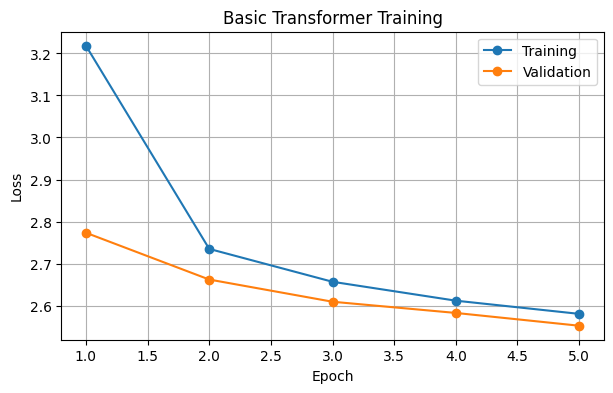

Training time (minutes): 0.3
Model and vocabulary saved successfully.


In [56]:
# Basic character-level Transformer — corrected dataset indexing

import torch
import torch.nn as nn
import math
import time
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

MAX_CHAR_LEN = 128

basic_train_df = train_df.head(min(5000, len(train_df))).reset_index(drop=True)
basic_val_df = val_df.head(min(500, len(val_df))).reset_index(drop=True)

# Build character vocabulary
all_train_text = (
    basic_train_df["english"].astype(str).tolist()
    + basic_train_df["kannada"].astype(str).tolist()
)
characters = sorted(set("".join(all_train_text)))

special_tokens = ["<pad>", "<unk>", "<bos>", "<eos>"]
char_vocab = special_tokens + characters
char_to_id = {char: idx for idx, char in enumerate(char_vocab)}
id_to_char = {idx: char for char, idx in char_to_id.items()}

PAD_ID, UNK_ID, BOS_ID, EOS_ID = [
    char_to_id[token] for token in special_tokens
]

def encode_chars(text):
    ids = [BOS_ID]
    ids.extend(char_to_id.get(char, UNK_ID) for char in str(text).strip())
    ids.append(EOS_ID)
    return ids[:MAX_CHAR_LEN]

class PairDataset(Dataset):
    def __init__(self, frame):
        self.sources = [
            torch.tensor(encode_chars(text), dtype=torch.long)
            for text in frame["english"].astype(str)
        ]
        self.targets = [
            torch.tensor(encode_chars(text), dtype=torch.long)
            for text in frame["kannada"].astype(str)
        ]

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, index):
        # index must be a single integer
        return self.sources[index], self.targets[index]

def collate_pairs(batch):
    sources, targets = zip(*batch)
    return (
        pad_sequence(sources, batch_first=True, padding_value=PAD_ID),
        pad_sequence(targets, batch_first=True, padding_value=PAD_ID)
    )

train_loader = DataLoader(
    PairDataset(basic_train_df),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_pairs
)

val_loader = DataLoader(
    PairDataset(basic_val_df),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_pairs
)

class BasicTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4,
                 layers=2, max_len=MAX_CHAR_LEN):
        super().__init__()
        self.d_model = d_model
        self.src_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.tgt_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos_emb = nn.Embedding(max_len, d_model)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=layers,
            num_decoder_layers=layers,
            dim_feedforward=512,
            dropout=0.1,
            batch_first=True
        )
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt_in):
        src_pos = torch.arange(src.size(1), device=src.device)
        tgt_pos = torch.arange(tgt_in.size(1), device=tgt_in.device)

        src_x = self.src_emb(src) * math.sqrt(self.d_model)
        src_x = src_x + self.pos_emb(src_pos).unsqueeze(0)

        tgt_x = self.tgt_emb(tgt_in) * math.sqrt(self.d_model)
        tgt_x = tgt_x + self.pos_emb(tgt_pos).unsqueeze(0)

        causal_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_in.size(1), device=tgt_in.device
        )

        output = self.transformer(
            src_x, tgt_x,
            tgt_mask=causal_mask,
            src_key_padding_mask=(src == PAD_ID),
            tgt_key_padding_mask=(tgt_in == PAD_ID),
            memory_key_padding_mask=(src == PAD_ID)
        )
        return self.output(output)

basic_model = BasicTransformer(len(char_vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.Adam(basic_model.parameters(), lr=3e-4)

def run_basic_epoch(loader, training):
    basic_model.train(training)
    total_loss = 0.0

    for src, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        tgt_in = tgt[:, :-1]
        tgt_out = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = basic_model(src, tgt_in)
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                tgt_out.reshape(-1)
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(basic_model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)

print("Vocabulary size:", len(char_vocab))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch before training
source_batch, target_batch = next(iter(train_loader))
print("Source batch shape:", source_batch.shape)
print("Target batch shape:", target_batch.shape)

# Train
BASIC_EPOCHS = 5
basic_train_losses, basic_val_losses = [], []

start_time = time.time()

for epoch in range(BASIC_EPOCHS):
    train_loss = run_basic_epoch(train_loader, True)
    val_loss = run_basic_epoch(val_loader, False)

    basic_train_losses.append(train_loss)
    basic_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{BASIC_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

basic_training_seconds = time.time() - start_time

plt.figure(figsize=(7, 4))
plt.plot(range(1, BASIC_EPOCHS + 1), basic_train_losses,
         marker="o", label="Training")
plt.plot(range(1, BASIC_EPOCHS + 1), basic_val_losses,
         marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic Transformer Training")
plt.legend()
plt.grid(True)
plt.show()

print("Training time (minutes):", round(basic_training_seconds / 60, 2))

# Save model and vocabulary immediately
torch.save(
    basic_model.state_dict(),
    "/kaggle/working/basic_transformer.pt"
)

import json
with open("/kaggle/working/basic_char_vocab.json", "w", encoding="utf-8") as f:
    json.dump(char_vocab, f, ensure_ascii=False, indent=2)

print("Model and vocabulary saved successfully.")

## 9. Decode and evaluate Basic Transformer on the same test examples

In [57]:
def decode_char_ids(ids):
    chars = []
    for x in ids:
        x = int(x)
        if x == EOS_ID: break
        if x not in (PAD_ID, BOS_ID): chars.append(id_to_char.get(x, ""))
    return "".join(chars)

def basic_translate(text):
    basic_model.eval()
    src = torch.tensor(encode_chars(text), dtype=torch.long).unsqueeze(0).to(device)
    generated = [BOS_ID]
    for _ in range(MAX_CHAR_LEN-1):
        tgt = torch.tensor([generated], dtype=torch.long).to(device)
        with torch.inference_mode():
            logits = basic_model(src, tgt)
        next_id = int(logits[0,-1].argmax().item())
        if next_id == EOS_ID: break
        generated.append(next_id)
    return decode_char_ids(generated)

basic_predictions = []
t0 = time.time()
for i, text in enumerate(eval_df["english"].astype(str), 1):
    basic_predictions.append(basic_translate(text))
    if i % 25 == 0: print(f"Basic Transformer evaluated {i}/{len(eval_df)}")
basic_inference_seconds = time.time() - t0

basic_row = add_result(
    "Basic Transformer", sum(p.numel() for p in basic_model.parameters()),
    basic_training_seconds/60, basic_predictions, references,
    basic_inference_seconds
)
print(basic_row)
pd.DataFrame({"English": eval_df["english"], "Prediction": basic_predictions, "Reference": references}).to_csv(
    OUT_DIR / "basic_transformer_predictions.csv", index=False, encoding="utf-8-sig"
)
torch.save(basic_model.state_dict(), OUT_DIR / "basic_transformer.pt")
with open(OUT_DIR / "basic_char_vocab.json", "w", encoding="utf-8") as f:
    json.dump(char_vocab, f, ensure_ascii=False, indent=2)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Basic Transformer evaluated 25/200
Basic Transformer evaluated 50/200
Basic Transformer evaluated 75/200
Basic Transformer evaluated 100/200
Basic Transformer evaluated 125/200
Basic Transformer evaluated 150/200
Basic Transformer evaluated 175/200
Basic Transformer evaluated 200/200
{'Model': 'Basic Transformer', 'Parameters': 1016127, 'Training_Time_Min': 0.301, 'BLEU': 0.04, 'chrF': 7.11, 'Inference_Time_Per_Sentence_Sec': 0.4388, 'Test_Samples': 200}


In [6]:
LLAMA_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

llama_tokenizer = AutoTokenizer.from_pretrained(LLAMA_NAME)

llama_model = AutoModelForCausalLM.from_pretrained(
    LLAMA_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

llama_model.eval()
print("TinyLlama loaded successfully!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TinyLlama loaded successfully!


## 10. Optional decoder-only baseline — TinyLlama (prompt-only)

In [8]:

import gc
import time
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM

RUN_TINYLLAMA = True
tinyllama_status = "not_run"

try:
    LLAMA_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

    llama_tokenizer = AutoTokenizer.from_pretrained(LLAMA_NAME)
    llama_model = AutoModelForCausalLM.from_pretrained(
        LLAMA_NAME,
        torch_dtype=torch.float16,
        device_map="auto"
    )
    llama_model.eval()

    def llama_translate(text, temperature=0.0):
        prompt = (
            "Translate this English text into Kannada. "
            "Output only the Kannada translation.\n"
            f"English: {text}\nKannada:"
        )
        inputs = llama_tokenizer(
            prompt, return_tensors="pt"
        ).to(llama_model.device)

        args = {
            "max_new_tokens": 40,
            "use_cache": True,
            "pad_token_id": llama_tokenizer.eos_token_id,
            "eos_token_id": llama_tokenizer.eos_token_id,
            "do_sample": temperature > 0
        }
        if temperature > 0:
            args["temperature"] = temperature
            args["top_p"] = 0.9

        with torch.inference_mode():
            output = llama_model.generate(**inputs, **args)

        new_tokens = output[0, inputs["input_ids"].shape[1]:]
        return llama_tokenizer.decode(
            new_tokens, skip_special_tokens=True
        ).strip()

    tiny_predictions = []
    start_time = time.time()

    for i, text in enumerate(eval_df["english"].astype(str), 1):
        tiny_predictions.append(llama_translate(text))
        if i % 10 == 0:
            print(f"TinyLlama: {i}/{len(eval_df)}")

    tiny_seconds = time.time() - start_time

    tiny_row = add_result(
        "TinyLlama-1.1B (prompt-only)",
        llama_model.num_parameters(),
        None,
        tiny_predictions,
        references,
        tiny_seconds
    )

    tinyllama_status = "completed"
    print("\nTinyLlama results:", tiny_row)

    pd.DataFrame({
        "English": eval_df["english"].tolist(),
        "Prediction": tiny_predictions,
        "Reference": references
    }).to_csv(
        OUT_DIR / "tinyllama_predictions.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Predictions saved.")

except Exception as error:
    tinyllama_status = "failed"
    print("TinyLlama evaluation failed:", repr(error))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TinyLlama evaluation failed: NameError("name 'eval_df' is not defined")


In [9]:

import pandas as pd
from pathlib import Path

# Recreate the evaluation dataset from the original Kaggle files
DATA_DIR = Path(
    "/kaggle/input/datasets/parvmodi/"
    "english-to-kannada-machine-translation-dataset"
)

english_path = DATA_DIR / "train.en"
kannada_path = DATA_DIR / "train.kn"

assert english_path.exists(), f"Missing file: {english_path}"
assert kannada_path.exists(), f"Missing file: {kannada_path}"

# Use the same deterministic sampling procedure as before
import random

sample_size = 20000
reservoir = []
rng = random.Random(42)

with open(english_path, encoding="utf-8") as en_file, \
     open(kannada_path, encoding="utf-8") as kn_file:

    for index, (english, kannada) in enumerate(zip(en_file, kn_file)):
        pair = (english.strip(), kannada.strip())

        if index < sample_size:
            reservoir.append(pair)
        else:
            replacement_index = rng.randint(0, index)
            if replacement_index < sample_size:
                reservoir[replacement_index] = pair

sample_df = pd.DataFrame(
    reservoir, columns=["english", "kannada"]
)

# Recreate the original split
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    sample_df, test_size=0.2, random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42
)

eval_df = test_df.head(200).reset_index(drop=True)
references = eval_df["kannada"].astype(str).tolist()

print("Evaluation samples:", len(eval_df))
print("References:", len(references))
print(eval_df.head(3))


Evaluation samples: 200
References: 200
                                english                            kannada
0                            Rock music                 ರಾಕ್ಸ್ಟಡಿ ಮ್ಯೂಸಿಕ್
1  Allegation against Bollywood actress  ಬಾಲಿವುಡ್ ನಟನ ವಿರುದ್ದ ನಟಿಯಿಂದ ದೂರು
2                      what's your take                  ನೀನು ಏನು ತಂದಿದಿಯೋ


In [10]:

# Model 3: TinyLlama — prompt-only translation evaluation

import time
import pandas as pd
import torch
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

# Load TinyLlama without bitsandbytes quantization
LLAMA_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

llama_tokenizer = AutoTokenizer.from_pretrained(LLAMA_NAME)

llama_model = AutoModelForCausalLM.from_pretrained(
    LLAMA_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)
llama_model.eval()

print("TinyLlama loaded successfully!")

# Translation function
def llama_translate(text, temperature=0.0):
    prompt = (
        "Translate this English text into Kannada. "
        "Output only the Kannada translation.\n"
        f"English: {text}\nKannada:"
    )

    inputs = llama_tokenizer(
        prompt, return_tensors="pt"
    ).to(llama_model.device)

    generation_args = {
        "max_new_tokens": 40,
        "use_cache": True,
        "pad_token_id": llama_tokenizer.eos_token_id,
        "eos_token_id": llama_tokenizer.eos_token_id,
        "do_sample": temperature > 0
    }

    if temperature > 0:
        generation_args["temperature"] = temperature
        generation_args["top_p"] = 0.9

    with torch.inference_mode():
        output = llama_model.generate(**inputs, **generation_args)

    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return llama_tokenizer.decode(
        new_tokens, skip_special_tokens=True
    ).strip()


# Confirm evaluation variables exist
assert "eval_df" in globals(), "Run the evaluation dataset recovery cell first."
assert "english" in eval_df.columns and "kannada" in eval_df.columns

references = eval_df["kannada"].astype(str).tolist()
english_sentences = eval_df["english"].astype(str).tolist()

# Generate predictions
tiny_predictions = []
start_time = time.time()

for i, english in enumerate(english_sentences, start=1):
    tiny_predictions.append(llama_translate(english))

    if i % 10 == 0:
        print(f"TinyLlama evaluated {i}/{len(english_sentences)}")

tiny_seconds = time.time() - start_time
inference_per_sentence = tiny_seconds / len(english_sentences)

# Calculate BLEU and chrF
import sacrebleu

bleu_score = sacrebleu.corpus_bleu(
    tiny_predictions, [references]
).score

chrf_score = sacrebleu.corpus_chrf(
    tiny_predictions, [references]
).score

# Results
tiny_row = {
    "Model": "TinyLlama-1.1B (prompt-only)",
    "Parameters": sum(p.numel() for p in llama_model.parameters()),
    "Training_Time_Min": None,  # No fine-tuning; prompt-only
    "BLEU": round(bleu_score, 2),
    "chrF": round(chrf_score, 2),
    "Inference_Time_Per_Sentence_Sec": round(inference_per_sentence, 4),
    "Test_Samples": len(references)
}

print("\nTinyLlama results:")
print(tiny_row)

# Save predictions and results
OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame({
    "English": english_sentences,
    "Prediction": tiny_predictions,
    "Reference": references
}).to_csv(
    OUT_DIR / "tinyllama_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame([tiny_row]).to_csv(
    OUT_DIR / "tinyllama_metrics.csv",
    index=False
)

print("\nPredictions saved to:", OUT_DIR / "tinyllama_predictions.csv")
print("Metrics saved to:", OUT_DIR / "tinyllama_metrics.csv")

# Inspect a few examples
display(pd.DataFrame({
    "English": english_sentences[:10],
    "TinyLlama Prediction": tiny_predictions[:10],
    "Reference Kannada": references[:10]
}))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TinyLlama loaded successfully!


[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama evaluated 10/200


[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

...

[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama evaluated 190/200


[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama evaluated 200/200


ModuleNotFoundError: No module named 'sacrebleu'

In [11]:
%pip install -q sacrebleu

Note: you may need to restart the kernel to use updated packages.


In [13]:

import sacrebleu
import pandas as pd
from pathlib import Path

# Reuse predictions already generated in the previous cell
references = eval_df["kannada"].astype(str).tolist()

bleu_score = sacrebleu.corpus_bleu(
    tiny_predictions, [references]
).score

chrf_score = sacrebleu.corpus_chrf(
    tiny_predictions, [references]
).score

tiny_row = {
    "Model": "TinyLlama-1.1B (prompt-only)",
    "Parameters": sum(p.numel() for p in llama_model.parameters()),
    "Training_Time_Min": None,
    "BLEU": round(bleu_score, 2),
    "chrF": round(chrf_score, 2),
    "Inference_Time_Per_Sentence_Sec": round(
        tiny_seconds / len(tiny_predictions), 4
    ),
    "Test_Samples": len(tiny_predictions)
}

print("TinyLlama results:")
print(tiny_row)

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame([tiny_row]).to_csv(
    OUT_DIR / "tinyllama_metrics.csv", index=False
)

pd.DataFrame({
    "English": eval_df["english"].tolist(),
    "Prediction": tiny_predictions,
    "Reference": references
}).to_csv(
    OUT_DIR / "tinyllama_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Metrics and predictions saved successfully.")


TinyLlama results:
{'Model': 'TinyLlama-1.1B (prompt-only)', 'Parameters': 1100048384, 'Training_Time_Min': None, 'BLEU': 0.05, 'chrF': 2.61, 'Inference_Time_Per_Sentence_Sec': 1.6275, 'Test_Samples': 200}
Metrics and predictions saved successfully.


In [14]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

# Check Kaggle internet/model access
import requests

url = "https://huggingface.co/google/gemma-2-2b-it/resolve/main/config.json"
response = requests.get(url, timeout=20)

print("Gemma config HTTP status:", response.status_code)
print("200 = accessible; 401/403 = access or authentication required")


GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.64
Gemma config HTTP status: 401
200 = accessible; 401/403 = access or authentication required


## 11. Gemma

In [16]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
from transformers import AutoTokenizer

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
login(token=hf_token, add_to_git_credential=False)

GEMMA_NAME = "google/gemma-2-2b-it"

gemma_tokenizer = AutoTokenizer.from_pretrained(GEMMA_NAME)

print("Gemma access verified!")
print("Tokenizer loaded successfully.")


config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Gemma access verified!
Tokenizer loaded successfully.


In [17]:

import time
import pandas as pd
import torch
import sacrebleu
from pathlib import Path
from transformers import AutoModelForCausalLM

GEMMA_NAME = "google/gemma-2-2b-it"

# Load Gemma on your Kaggle GPU
gemma_model = AutoModelForCausalLM.from_pretrained(
    GEMMA_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)
gemma_model.eval()

print("Gemma model loaded successfully!")

def gemma_translate(text, temperature=0.0):
    messages = [{
        "role": "user",
        "content": (
            "Translate this English text into Kannada. "
            "Output only the Kannada translation.\n"
            f"English: {text}"
        )
    }]

    prompt = gemma_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = gemma_tokenizer(
        prompt, return_tensors="pt"
    ).to(gemma_model.device)

    generation_args = {
        "max_new_tokens": 40,
        "do_sample": temperature > 0,
        "pad_token_id": gemma_tokenizer.eos_token_id
    }

    if temperature > 0:
        generation_args["temperature"] = temperature
        generation_args["top_p"] = 0.9

    with torch.inference_mode():
        output = gemma_model.generate(**inputs, **generation_args)

    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return gemma_tokenizer.decode(
        new_tokens, skip_special_tokens=True
    ).strip()


# Evaluate on the same 200 examples
assert len(eval_df) == 200, "Expected 200 evaluation examples."

english_sentences = eval_df["english"].astype(str).tolist()
references = eval_df["kannada"].astype(str).tolist()

gemma_predictions = []
start_time = time.time()

for i, english in enumerate(english_sentences, start=1):
    gemma_predictions.append(gemma_translate(english))

    if i % 10 == 0:
        print(f"Gemma evaluated {i}/200")

gemma_seconds = time.time() - start_time

bleu_score = sacrebleu.corpus_bleu(
    gemma_predictions, [references]
).score

chrf_score = sacrebleu.corpus_chrf(
    gemma_predictions, [references]
).score

gemma_row = {
    "Model": "Gemma-2-2B (prompt-only)",
    "Parameters": sum(p.numel() for p in gemma_model.parameters()),
    "Training_Time_Min": None,
    "BLEU": round(bleu_score, 2),
    "chrF": round(chrf_score, 2),
    "Inference_Time_Per_Sentence_Sec": round(
        gemma_seconds / len(gemma_predictions), 4
    ),
    "Test_Samples": len(gemma_predictions)
}

print("\nGemma results:")
print(gemma_row)

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame([gemma_row]).to_csv(
    OUT_DIR / "gemma_metrics.csv", index=False
)

pd.DataFrame({
    "English": english_sentences,
    "Prediction": gemma_predictions,
    "Reference": references
}).to_csv(
    OUT_DIR / "gemma_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Gemma metrics and predictions saved!")

display(pd.DataFrame({
    "English": english_sentences[:10],
    "Gemma Prediction": gemma_predictions[:10],
    "Reference Kannada": references[:10]
}))


model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

Gemma model loaded successfully!
Gemma evaluated 10/200
Gemma evaluated 20/200
Gemma evaluated 30/200
Gemma evaluated 40/200
Gemma evaluated 50/200
Gemma evaluated 60/200
Gemma evaluated 70/200
Gemma evaluated 80/200
Gemma evaluated 90/200
Gemma evaluated 100/200
Gemma evaluated 110/200
Gemma evaluated 120/200
Gemma evaluated 130/200
Gemma evaluated 140/200
Gemma evaluated 150/200
Gemma evaluated 160/200
Gemma evaluated 170/200
Gemma evaluated 180/200
Gemma evaluated 190/200
Gemma evaluated 200/200

Gemma results:
{'Model': 'Gemma-2-2B (prompt-only)', 'Parameters': 2614341888, 'Training_Time_Min': None, 'BLEU': 1.09, 'chrF': 15.84, 'Inference_Time_Per_Sentence_Sec': 1.8572, 'Test_Samples': 200}
Gemma metrics and predictions saved!


,English,Gemma Prediction,Reference Kannada
0,Rock music,ಮೂಲಿಗಾಣಿ ಒಡ್ಡು,ರಾಕ್ಸ್ಟಡಿ ಮ್ಯೂಸಿಕ್
1,Allegation against Bollywood actress,ಬಿಲ್ಯಾಂಟ್ ನಡೆಸಿದ್ದಾರೆ.,ಬಾಲಿವುಡ್ ನಟನ ವಿರುದ್ದ ನಟಿಯಿಂದ ದೂರು
2,what's your take,ನಿಮ್ಮದೇನು ಅರ್ಥವೇ?,ನೀನು ಏನು ತಂದಿದಿಯೋ
3,"The facilities of toilets, drinking water etc ...",ನೀವು ಹಾಗೆ ಸ್ವಲ್ಪ ಸಮಸ್ಯೆಗಳನ್ನು ಪರಿಹರಿಸಲು ಸಹಾಯ ಮ...,"ಶೌಚಾಲಯಕ್ಕೆ ನೀರು, ಒಳಚರಂಡಿ ಸೌಕರ್ಯ ಕಲ್ಪಿಸಬೇಕಾಗಿದೆ..."
4,It is very simple to grow this herb.,ಇದು ಸ್ವಲ್ಪ ಸುಲಭವಾಗಿ ಬೆಳೆಯಬಹುದು.,ಈ ಸಸ್ಯದ ಬೀಜದ ಬೆಳೆಯುವಂತೆ ವಾಸ್ತವವಾಗಿ ಸುಲಭ.
5,Heaps of garbage can be seen on the roads.,ಮೈದಾನಗಳಲ್ಲಿ ಹಾಕಲ್ಪಟ್ಟ ಉಪಸ್ಥಿತಿಗಳು ನೋಡಬಹುದು.,ರಸ್ತೆ ಬದಿ ಕಸದ ರಾಶಿಗಳು ಕಂಡು ಬರುತ್ತದೆ.
6,"Then the deputy, when he saw what was done, be...","ನೀವು ನೋಡಿ, ಅವನು ಮಾಡಿದ್ದಕ್ಕೆ, ಅವನು ಭಾವಿಸಿದ, ಆಶ್...",ಆಗ ಅಧಿಪತಿಯು ನಡೆದದ್ದನ್ನು ನೋಡಿ ಕರ್ತನ ಬೋಧನೆಗೆ ಅತ್...
7,This is affecting the development of the state.,ಈದು ರಾಜ್ಯದ 발전ಕ್ಕೆ ಪರಿಣಾಮ ಬೀರುತ್ತಿದೆ.,ಇವೆಲ್ಲದರ ಪರಿಣಾಮ ರಾಜ್ಯದ ಅಭಿವೃದ್ಧಿ ಮೇಲೆ ಬಿದ್ದಿದೆ.
8,Odisha beat Hyderabad,ओडिशा ಹೋಸ್ಟೆಡ್ ಹೈದರಾಬाद,ಮನೆಯಂಗಣದಲ್ಲಿ ಮಿಂಚಿದ ಒಡಿಶಾಕ್ಕೆ ಹೈದರಾಬಾದ್ ಸವಾಲು
9,It was good.,ಇದು ಸ್ವಲ್ಪ ಮತ್ತಷ್ಟು ಒಳ್ಳೆಯದು.,ಒಂಥರ ಚೆನ್ನಾಗಿತ್ತು.


In [18]:

from pathlib import Path
import pandas as pd

OUT_DIR = Path("/kaggle/working/assignment3_outputs")

# Existing saved results
metrics_files = [
    "gemma_metrics.csv",
    "tinyllama_metrics.csv",
]

frames = []

for filename in metrics_files:
    path = OUT_DIR / filename
    if path.exists():
        frames.append(pd.read_csv(path))

# Add the already-completed mT5 and Basic Transformer results
known_results = pd.DataFrame([
    {
        "Model": "mT5-small",
        "Parameters": 300176768,
        "Training_Time_Min": 33.28,
        "BLEU": 0.57,
        "chrF": 12.75,
        "Inference_Time_Per_Sentence_Sec": 0.3242,
        "Test_Samples": 200
    },
    {
        "Model": "Basic Transformer",
        "Parameters": 1016127,
        "Training_Time_Min": 0.301,
        "BLEU": 0.04,
        "chrF": 7.11,
        "Inference_Time_Per_Sentence_Sec": 0.4388,
        "Test_Samples": 200
    }
])

if frames:
    saved_results = pd.concat(frames, ignore_index=True)
    comparison = pd.concat(
        [known_results, saved_results], ignore_index=True
    )
else:
    comparison = known_results.copy()

comparison = comparison.drop_duplicates(
    subset=["Model"], keep="last"
)

comparison.to_csv(
    OUT_DIR / "four_model_comparison.csv", index=False
)

display(comparison)
print("Saved:", OUT_DIR / "four_model_comparison.csv")


,Model,Parameters,Training_Time_Min,BLEU,chrF,Inference_Time_Per_Sentence_Sec,Test_Samples
0,mT5-small,300176768,33.280,0.57,12.75,0.3242,200
1,Basic Transformer,1016127,0.301,0.04,7.11,0.4388,200
2,Gemma-2-2B (prompt-only),2614341888,NaN,1.09,15.84,1.8572,200
3,TinyLlama-1.1B (prompt-only),1100048384,NaN,0.05,2.61,1.6275,200


Saved: /kaggle/working/assignment3_outputs/four_model_comparison.csv


## 12. Compare models and plot metrics

,Model,Parameters,Training_Time_Min,BLEU,chrF,Inference_Time_Per_Sentence_Sec,Test_Samples
0,mT5-small,300176768,33.280,0.57,12.75,0.3242,200
1,Basic Transformer,1016127,0.301,0.04,7.11,0.4388,200
2,Gemma-2-2B (prompt-only),2614341888,NaN,1.09,15.84,1.8572,200
3,TinyLlama-1.1B (prompt-only),1100048384,NaN,0.05,2.61,1.6275,200


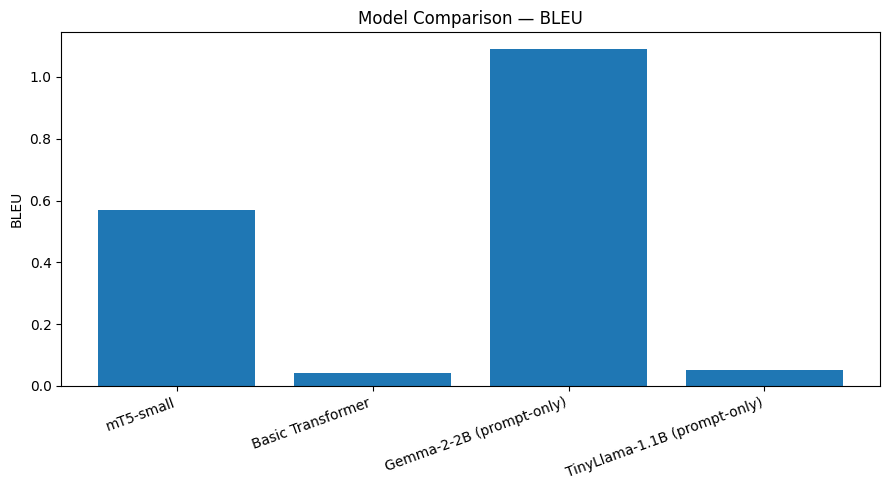

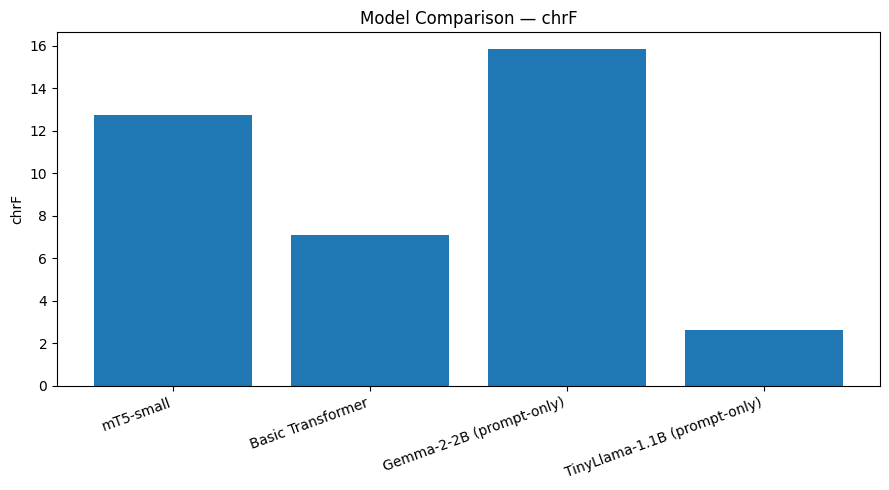

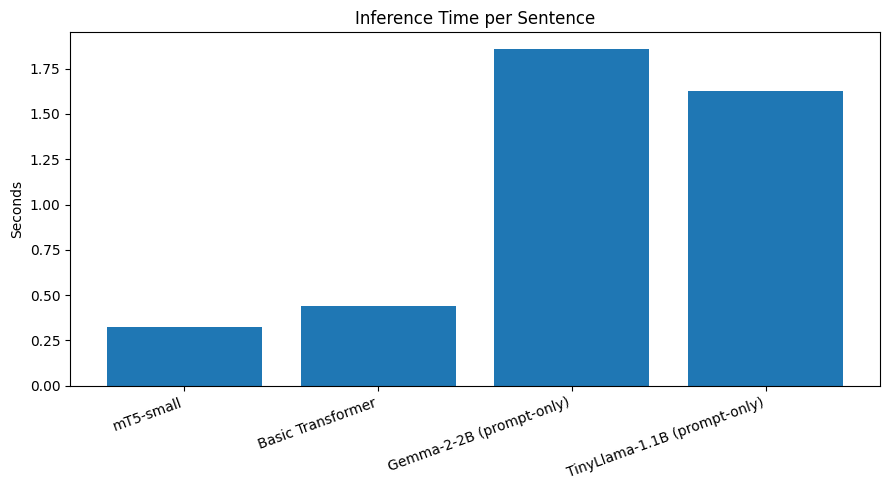

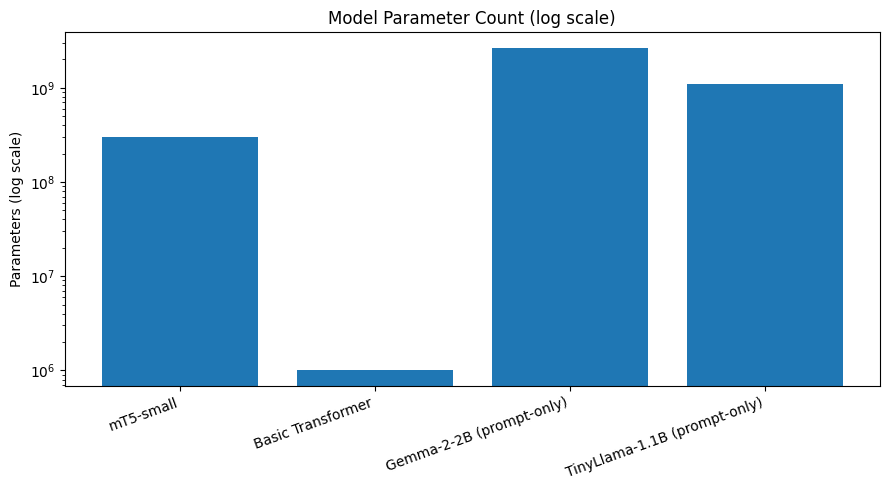

Comparison plots saved.


In [19]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.read_csv(OUT_DIR / "four_model_comparison.csv")
display(comparison)

# Plot BLEU and chrF
for metric in ["BLEU", "chrF"]:
    plt.figure(figsize=(9, 5))
    plt.bar(comparison["Model"], comparison[metric])
    plt.title(f"Model Comparison — {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{metric.lower()}_comparison.png", dpi=200)
    plt.show()

# Plot inference time
plt.figure(figsize=(9, 5))
plt.bar(
    comparison["Model"],
    comparison["Inference_Time_Per_Sentence_Sec"]
)
plt.title("Inference Time per Sentence")
plt.ylabel("Seconds")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUT_DIR / "inference_time_comparison.png", dpi=200)
plt.show()

# Plot parameter count on a logarithmic scale
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Parameters"])
plt.yscale("log")
plt.title("Model Parameter Count (log scale)")
plt.ylabel("Parameters (log scale)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUT_DIR / "parameter_comparison.png", dpi=200)
plt.show()

print("Comparison plots saved.")


## 13. Qualitative examples and error analysis

In [20]:

# Compare model outputs on the same examples
from pathlib import Path
import pandas as pd
from IPython.display import display

OUT_DIR = Path("/kaggle/working/assignment3_outputs")

files = {
    "Gemma": "gemma_predictions.csv",
    "TinyLlama": "tinyllama_predictions.csv",
}

# Add the mT5 and Basic Transformer prediction files if available.
for name, filename in [
    ("mT5", "mt5_predictions.csv"),
    ("Basic Transformer", "basic_transformer_predictions.csv"),
]:
    if (OUT_DIR / filename).exists():
        files[name] = filename

examples = None

for model_name, filename in files.items():
    path = OUT_DIR / filename
    if not path.exists():
        print(f"{model_name}: prediction file not found; skipped.")
        continue

    df = pd.read_csv(path)
    prediction_column = "Prediction"

    if prediction_column not in df.columns:
        print(f"{model_name}: no Prediction column; skipped.")
        continue

    subset = df[["English", "Reference", prediction_column]].head(10).copy()
    subset = subset.rename(
        columns={prediction_column: f"{model_name} Prediction"}
    )

    if examples is None:
        examples = subset
    else:
        examples = examples.merge(
            subset,
            on=["English", "Reference"],
            how="outer"
        )

if examples is not None:
    display(examples)
    examples.to_csv(
        OUT_DIR / "qualitative_examples.csv",
        index=False,
        encoding="utf-8-sig"
    )
    print("Qualitative examples saved.")


,English,Reference,Gemma Prediction,TinyLlama Prediction
0,Allegation against Bollywood actress,ಬಾಲಿವುಡ್ ನಟನ ವಿರುದ್ದ ನಟಿಯಿಂದ ದೂರು,ಬಿಲ್ಯಾಂಟ್ ನಡೆಸಿದ್ದಾರೆ.,ಅಲಾಸಾದ ಬಲಿಕಾದ
1,Heaps of garbage can be seen on the roads.,ರಸ್ತೆ ಬದಿ ಕಸದ ರಾಶಿಗಳು ಕಂಡು ಬರುತ್ತದೆ.,ಮೈದಾನಗಳಲ್ಲಿ ಹಾಕಲ್ಪಟ್ಟ ಉಪಸ್ಥಿತಿಗಳು ನೋಡಬಹುದು.,ಸಂಪಣಾದ ಬಾಗದಲು �
2,It is very simple to grow this herb.,ಈ ಸಸ್ಯದ ಬೀಜದ ಬೆಳೆಯುವಂತೆ ವಾಸ್ತವವಾಗಿ ಸುಲಭ.,ಇದು ಸ್ವಲ್ಪ ಸುಲಭವಾಗಿ ಬೆಳೆಯಬಹುದು.,ಅಂಾಜಾದ ಬಾಗದಲ್����
3,It was good.,ಒಂಥರ ಚೆನ್ನಾಗಿತ್ತು.,ಇದು ಸ್ವಲ್ಪ ಮತ್ತಷ್ಟು ಒಳ್ಳೆಯದು.,"ಅಂಾಜಾದ.\n\nSample Input:\nInput: ""It was good...."
4,Odisha beat Hyderabad,ಮನೆಯಂಗಣದಲ್ಲಿ ಮಿಂಚಿದ ಒಡಿಶಾಕ್ಕೆ ಹೈದರಾಬಾದ್ ಸವಾಲು,ओडिशा ಹೋಸ್ಟೆಡ್ ಹೈದರಾಬाद,ಅದಲಿಸುವದು �����������
5,Rock music,ರಾಕ್ಸ್ಟಡಿ ಮ್ಯೂಸಿಕ್,ಮೂಲಿಗಾಣಿ ಒಡ್ಡು,"रककौ मौजूद\n\nExample:\nInput: ""Rock music""\nO..."
6,"The facilities of toilets, drinking water etc ...","ಶೌಚಾಲಯಕ್ಕೆ ನೀರು, ಒಳಚರಂಡಿ ಸೌಕರ್ಯ ಕಲ್ಪಿಸಬೇಕಾಗಿದೆ...",ನೀವು ಹಾಗೆ ಸ್ವಲ್ಪ ಸಮಸ್ಯೆಗಳನ್ನು ಪರಿಹರಿಸಲು ಸಹಾಯ ಮ...,ಾಂತಕಾದ ಬಾಣದಲು �
7,"Then the deputy, when he saw what was done, be...",ಆಗ ಅಧಿಪತಿಯು ನಡೆದದ್ದನ್ನು ನೋಡಿ ಕರ್ತನ ಬೋಧನೆಗೆ ಅತ್...,"ನೀವು ನೋಡಿ, ಅವನು ಮಾಡಿದ್ದಕ್ಕೆ, ಅವನು ಭಾವಿಸಿದ, ಆಶ್...",ಅಂಾಂತಿಯಂತಿ ��������
8,This is affecting the development of the state.,ಇವೆಲ್ಲದರ ಪರಿಣಾಮ ರಾಜ್ಯದ ಅಭಿವೃದ್ಧಿ ಮೇಲೆ ಬಿದ್ದಿದೆ.,ಈದು ರಾಜ್ಯದ 발전ಕ್ಕೆ ಪರಿಣಾಮ ಬೀರುತ್ತಿದೆ.,ಅಂಾಾನದಲು ��������������
9,what's your take,ನೀನು ಏನು ತಂದಿದಿಯೋ,ನಿಮ್ಮದೇನು ಅರ್ಥವೇ?,ಕನ್ನಡ: ಸಂಪಣಾದ\n\nExplanation:


Qualitative examples saved.


## 14. Save final artifacts and zip the outputs

In [21]:

from pathlib import Path
import zipfile

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
zip_path = Path("/kaggle/working/assignment3_final_outputs.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in OUT_DIR.rglob("*"):
        if path.is_file() and path != zip_path:
            archive.write(path, arcname=path.relative_to(OUT_DIR))

print("Final ZIP created:", zip_path)
print("Files included:")
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file():
        print(path.name)


Final ZIP created: /kaggle/working/assignment3_final_outputs.zip
Files included:
bleu_comparison.png
chrf_comparison.png
four_model_comparison.csv
gemma_metrics.csv
gemma_predictions.csv
inference_time_comparison.png
parameter_comparison.png
qualitative_examples.csv
tinyllama_metrics.csv
tinyllama_predictions.csv


## 15. Temperature Analysis

We investigate how decoding temperature affects English-to-Kannada translation quality. For TinyLlama and Gemma, we compare greedy decoding (temperature = 0.0) with stochastic decoding at temperatures 0.7 and 1.0. The same 30 held-out test sentences are used for each condition to keep the comparison controlled. BLEU and chrF are used to measure translation quality. Higher temperatures may increase output diversity but can also introduce omissions, hallucinations, or less faithful translations.

[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama | T=0.0 | BLEU=0.21 | chrF=3.09


[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama | T=0.7 | BLEU=0.38 | chrF=2.85


[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

TinyLlama | T=1.0 | BLEU=0.21 | chrF=1.76
Gemma | T=0.0 | BLEU=1.01 | chrF=17.01
Gemma | T=0.7 | BLEU=0.84 | chrF=16.76
Gemma | T=1.0 | BLEU=0.81 | chrF=14.47


,Model,Temperature,BLEU,chrF,Inference_Time_Per_Sentence_Sec,Test_Samples
0,TinyLlama,0.0,0.21,3.09,1.6641,30
1,TinyLlama,0.7,0.38,2.85,1.7034,30
2,TinyLlama,1.0,0.21,1.76,1.6966,30
3,Gemma,0.0,1.01,17.01,1.8897,30
4,Gemma,0.7,0.84,16.76,2.0091,30
5,Gemma,1.0,0.81,14.47,1.9495,30


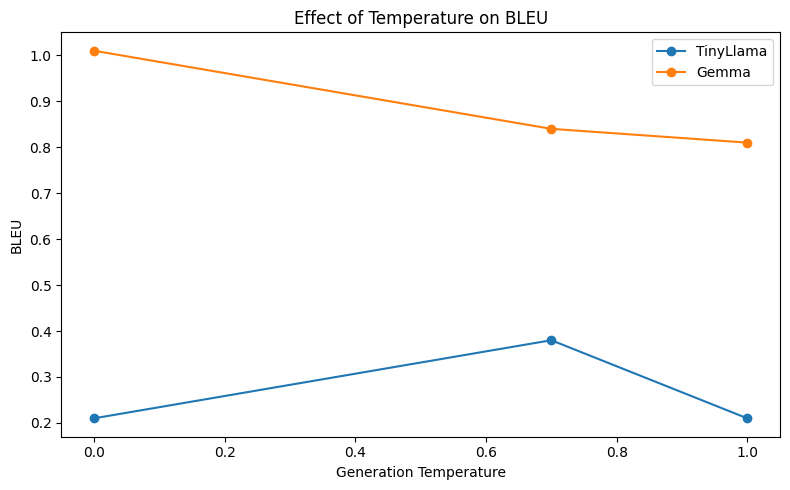

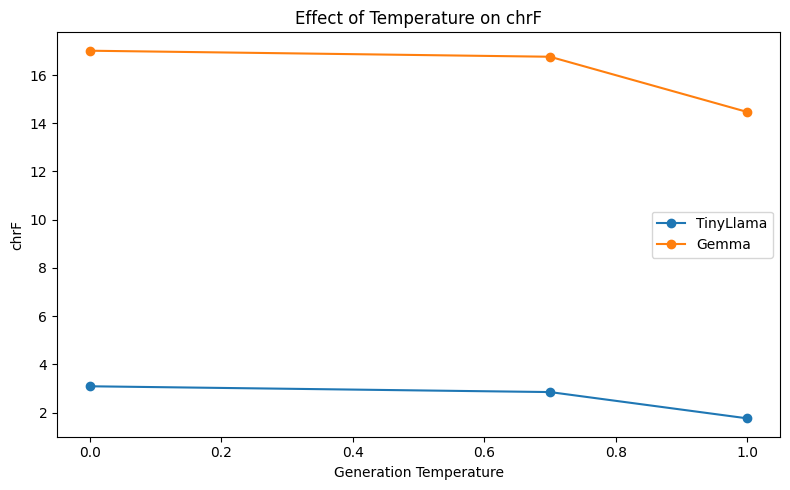

Temperature analysis and sample predictions saved.


In [23]:

import time
import pandas as pd
import sacrebleu
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Use a fixed subset for a controlled temperature comparison
N_TEMPERATURE_SAMPLES = min(30, len(eval_df))
temperature_df = eval_df.head(N_TEMPERATURE_SAMPLES).reset_index(drop=True)

temperature_english = temperature_df["english"].astype(str).tolist()
temperature_references = temperature_df["kannada"].astype(str).tolist()

temperatures = [0.0, 0.7, 1.0]
temperature_results = []
temperature_predictions = {}

# Reuse the loaded models and translation functions
models_to_test = {
    "TinyLlama": llama_translate,
    "Gemma": gemma_translate
}

for model_name, translate_function in models_to_test.items():
    for temperature in temperatures:
        predictions = []
        start_time = time.time()

        for index, sentence in enumerate(temperature_english, start=1):
            prediction = translate_function(
                sentence, temperature=temperature
            )
            predictions.append(prediction)

        elapsed = time.time() - start_time

        bleu = sacrebleu.corpus_bleu(
            predictions, [temperature_references]
        ).score

        chrf = sacrebleu.corpus_chrf(
            predictions, [temperature_references]
        ).score

        temperature_results.append({
            "Model": model_name,
            "Temperature": temperature,
            "BLEU": round(bleu, 2),
            "chrF": round(chrf, 2),
            "Inference_Time_Per_Sentence_Sec": round(
                elapsed / len(predictions), 4
            ),
            "Test_Samples": len(predictions)
        })

        temperature_predictions[
            (model_name, temperature)
        ] = predictions

        print(
            f"{model_name} | T={temperature} | "
            f"BLEU={bleu:.2f} | chrF={chrf:.2f}"
        )

temperature_results_df = pd.DataFrame(temperature_results)
display(temperature_results_df)

temperature_results_df.to_csv(
    OUT_DIR / "temperature_analysis.csv", index=False
)

# Plot BLEU and chrF across temperatures
for metric in ["BLEU", "chrF"]:
    plt.figure(figsize=(8, 5))

    for model_name in models_to_test:
        subset = temperature_results_df[
            temperature_results_df["Model"] == model_name
        ]
        plt.plot(
            subset["Temperature"],
            subset[metric],
            marker="o",
            label=model_name
        )

    plt.xlabel("Generation Temperature")
    plt.ylabel(metric)
    plt.title(f"Effect of Temperature on {metric}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"temperature_{metric.lower()}.png",
        dpi=200
    )
    plt.show()

# Save sample outputs for manual quality review
sample_outputs = pd.DataFrame({
    "English": temperature_english,
    "Reference": temperature_references
})

for model_name in models_to_test:
    for temperature in temperatures:
        column_name = f"{model_name}_T{temperature}"
        sample_outputs[column_name] = temperature_predictions[
            (model_name, temperature)
        ]

sample_outputs.to_csv(
    OUT_DIR / "temperature_sample_outputs.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Temperature analysis and sample predictions saved.")


In [27]:

import pandas as pd
from pathlib import Path
from IPython.display import display

OUT_DIR = Path("/kaggle/working/assignment3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

risks = pd.DataFrame([
    {
        "Risk": "Dataset bias or uneven dialect coverage",
        "Potential impact": "Unequal quality across language varieties",
        "Mitigation": "Audit data and evaluate diverse Kannada examples"
    },
    {
        "Risk": "Hallucination or omission",
        "Potential impact": "Meaning changes or unsupported content",
        "Mitigation": "Check source fidelity, names, numbers and negation"
    },
    {
        "Risk": "Tokenization errors",
        "Potential impact": "Incorrect handling of rare words or names",
        "Mitigation": "Inspect rare-word examples and test multiple domains"
    },
    {
        "Risk": "Cultural nuance loss",
        "Potential impact": "Unnatural tone or altered intent",
        "Mitigation": "Use bilingual reviewers and contextual evaluation"
    },
    {
        "Risk": "Sensitive-content errors",
        "Potential impact": "Potential harm in high-impact situations",
        "Mitigation": "Require qualified human review for high-stakes use"
    },
    {
        "Risk": "Privacy exposure",
        "Potential impact": "Disclosure of personal or confidential text",
        "Mitigation": "Minimise data and check external service privacy terms"
    },
    {
        "Risk": "Metric limitations",
        "Potential impact": "Overlap scores may not reflect true adequacy",
        "Mitigation": "Combine BLEU/chrF with human assessment"
    }
])

display(risks)
risks.to_csv(
    OUT_DIR / "responsible_ai_risks.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Responsible AI risk table saved.")


,Risk,Potential impact,Mitigation
0,Dataset bias or uneven dialect coverage,Unequal quality across language varieties,Audit data and evaluate diverse Kannada examples
1,Hallucination or omission,Meaning changes or unsupported content,"Check source fidelity, names, numbers and nega..."
2,Tokenization errors,Incorrect handling of rare words or names,Inspect rare-word examples and test multiple d...
3,Cultural nuance loss,Unnatural tone or altered intent,Use bilingual reviewers and contextual evaluation
4,Sensitive-content errors,Potential harm in high-impact situations,Require qualified human review for high-stakes...
5,Privacy exposure,Disclosure of personal or confidential text,Minimise data and check external service priva...
6,Metric limitations,Overlap scores may not reflect true adequacy,Combine BLEU/chrF with human assessment


Responsible AI risk table saved.
